### Validation metrics beyond aggregate correlation

Addresses PI review point 5: the current validation is a single system-level Pearson correlation (~0.88) against ERCOT Coast, which reviewers will find too coarse. This notebook adds: coincidence factor / diversity factor, load duration curves, diurnal shape (weekday/weekend, summer/winter), seasonal monthly behavior, and a documented proxy for spatial consistency (there is no per-bus ground truth to validate against, only the ERCOT Coast aggregate, so a true spatial-correlation validation is not possible with the data on hand — this is stated explicitly rather than glossed over).

Every metric is computed for **three** series where relevant: ERCOT actual, the original (leaky-trained) pipeline output, and the temporal (honest, `temporal_train_test.ipynb`) pipeline output — so this notebook also doubles as a second, independent check on whether fixing the training leak changes the shape-level validation story, not just the single correlation number already checked in the other notebook.

**Out of scope, needs input**: PI review point 9 asks for a comparison against "Hanyue's proportional load allocation method" from a prior synthetic-grid paper. I don't have that paper's method details, so I can't implement it here — flagging this at the end rather than guessing at an implementation.

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

exports = Path("loadcurves/exports")
assert exports.exists(), f"Expected exports dir at {exports.resolve()}"


#### Load ERCOT actual + both pipeline outputs (original vs temporal)

In [2]:
# --- ERCOT (same DST-aware parsing as plot_all.ipynb / temporal_train_test.ipynb) ---
file_path = exports / "Native_Load_2018.xlsx"
ercot_df = pd.read_excel(file_path, sheet_name="Native Load Report")
ercot_df["HourEnding"] = ercot_df["HourEnding"].astype(str)

is_dst_mask = ercot_df["HourEnding"].str.contains(" DST", regex=False)
ercot_df["HourEnding"] = ercot_df["HourEnding"].str.replace(" DST", "", regex=False)
mask_24 = ercot_df["HourEnding"].str.contains("24:00")
ercot_df["HourEnding"] = ercot_df["HourEnding"].str.replace("24:00", "00:00")

naive_timestamps = pd.to_datetime(ercot_df["HourEnding"])
naive_timestamps.loc[mask_24] += pd.Timedelta(days=1)

ercot_df["date_time"] = naive_timestamps.dt.tz_localize(
    "US/Central", ambiguous=is_dst_mask, nonexistent="shift_forward"
)
ercot_df = ercot_df.set_index("date_time")
ercot_df_est = ercot_df.tz_convert("Etc/GMT+5")

ercot_actual = ercot_df_est["COAST"].copy()
ercot_actual.index = ercot_actual.index.tz_localize(None)

# --- Bus-level profiles: original (leaky-trained) vs temporal (honest) ---
res_orig = pd.read_csv(exports / "final_bus_load_profiles_8760.csv", index_col=0, parse_dates=True)
com_orig = pd.read_csv(exports / "final_comstock_bus_load_profiles_8760.csv", index_col=0, parse_dates=True)
res_temp = pd.read_csv(exports / "final_bus_load_profiles_8760_temporal.csv", index_col=0, parse_dates=True)
com_temp = pd.read_csv(exports / "final_comstock_bus_load_profiles_8760_temporal.csv", index_col=0, parse_dates=True)

IND_BASE_MW, RES_SCALE, COM_SCALE = 4500.0, 1.9, 1.3


def calibrated_total_mw(res_df, com_df):
    total_res_mw = (res_df.sum(axis=1) / 1000) * RES_SCALE
    total_com_mw = (com_df.sum(axis=1) / 1000) * COM_SCALE
    return IND_BASE_MW + total_res_mw + total_com_mw


common_start = max(ercot_actual.index.min(), res_orig.index.min(), res_temp.index.min())
common_end = min(ercot_actual.index.max(), res_orig.index.max(), res_temp.index.max())

y_actual = ercot_actual.loc[common_start:common_end]
y_orig = calibrated_total_mw(res_orig, com_orig).loc[common_start:common_end]
y_temp = calibrated_total_mw(res_temp, com_temp).loc[common_start:common_end]

print(f"Common window: {common_start} to {common_end}  ({len(y_actual)} hours)")
print(f"Peaks (MW):  ERCOT={y_actual.max():,.0f}  Original={y_orig.max():,.0f}  Temporal={y_temp.max():,.0f}")


Common window: 2018-01-01 02:00:00 to 2019-01-01 00:00:00  (8759 hours)
Peaks (MW):  ERCOT=20,270  Original=24,418  Temporal=24,604


#### Coincidence factor / diversity factor

**Coincidence Factor (CF)** = (peak of the summed/coincident load across buses) / (sum of each bus's own individual peak). CF = 1 means every bus peaks at exactly the same hour (zero diversity); CF < 1 means peaks are spread out in time (the system peak is smoothed by diversity across buses). **Diversity Factor (DF) = 1/CF** (IEEE convention).

This metric is invariant to any uniform scale factor applied to every bus alike, so it is computed on the raw (uncalibrated) bus-level kWh — `RES_SCALE`/`COM_SCALE`/`IND_BASE_MW` would cancel out of the ratio and are not needed here.

In [3]:
def coincidence_diversity(bus_df, label):
    bus_peaks_sum = bus_df.max(axis=0).sum()          # sum of each bus's own peak
    system_peak = bus_df.sum(axis=1).max()             # peak of the coincident (summed) load
    cf = system_peak / bus_peaks_sum
    df_ = 1 / cf
    print(f"{label:28s} CF={cf:.4f}  DF={df_:.4f}  (n_buses={bus_df.shape[1]})")
    return cf, df_


print("--- Residential ---")
coincidence_diversity(res_orig, "Original")
coincidence_diversity(res_temp, "Temporal")

print("\n--- Commercial ---")
coincidence_diversity(com_orig, "Original")
coincidence_diversity(com_temp, "Temporal")

print("\n--- Combined (Res + Com, buses present in both) ---")
shared_buses_orig = res_orig.columns.intersection(com_orig.columns)
shared_buses_temp = res_temp.columns.intersection(com_temp.columns)
print(f"Shared buses: original={len(shared_buses_orig)}/200, temporal={len(shared_buses_temp)}/200 "
      f"(some buses have residential OR commercial load but not both, per the nearest-bus assignment)")

combined_orig = res_orig[shared_buses_orig] + com_orig[shared_buses_orig]
combined_temp = res_temp[shared_buses_temp] + com_temp[shared_buses_temp]
coincidence_diversity(combined_orig, "Original")
coincidence_diversity(combined_temp, "Temporal")


--- Residential ---
Original                     CF=0.9983  DF=1.0017  (n_buses=200)
Temporal                     CF=0.9957  DF=1.0043  (n_buses=200)

--- Commercial ---
Original                     CF=0.9984  DF=1.0016  (n_buses=200)
Temporal                     CF=0.9967  DF=1.0033  (n_buses=200)

--- Combined (Res + Com, buses present in both) ---
Shared buses: original=193/200, temporal=193/200 (some buses have residential OR commercial load but not both, per the nearest-bus assignment)
Original                     CF=0.9625  DF=1.0390  (n_buses=193)
Temporal                     CF=0.9789  DF=1.0216  (n_buses=193)


(np.float64(0.9788950842746221), np.float64(1.0215599363654144))

#### Load duration curve (LDC)

Sort hourly load descending and plot against % of hours the load is exceeded. Uses the calibrated stack (Industrial + Res*1.9 + Com*1.3) to compare shape against ERCOT on the same scale as the paper's headline validation.

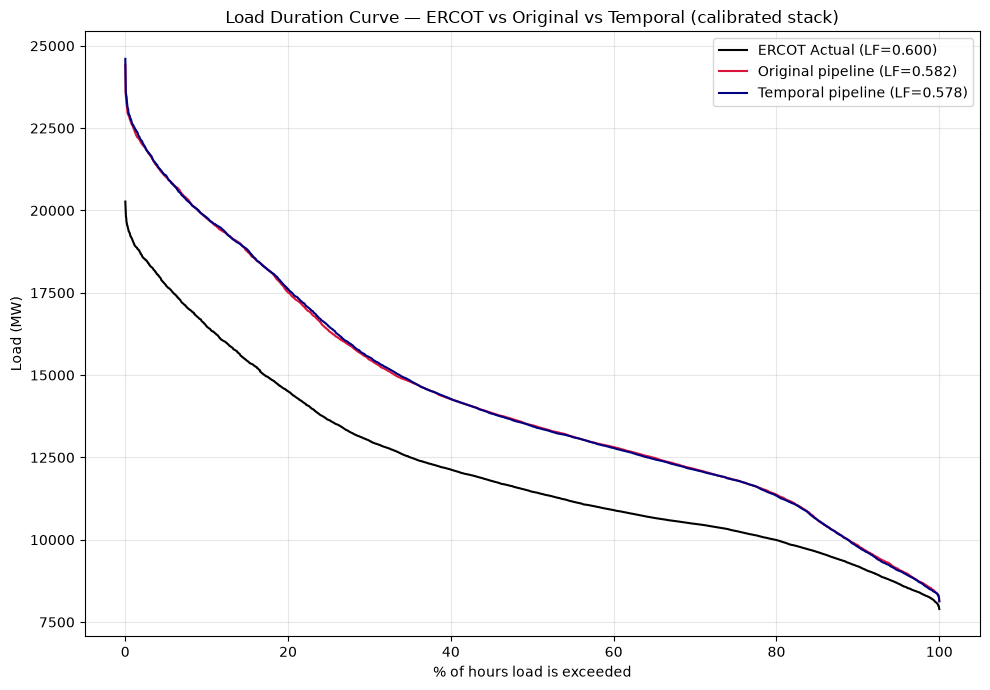

Load factor (mean/peak) — higher = flatter load shape:
  ERCOT Actual     0.6001
  Original         0.5819
  Temporal         0.5777


In [4]:
def load_factor(series):
    return series.mean() / series.max()


fig, ax = plt.subplots(figsize=(10, 7))
for series, label, color in [(y_actual, "ERCOT Actual", "black"),
                              (y_orig, "Original pipeline", "crimson"),
                              (y_temp, "Temporal pipeline", "navy")]:
    sorted_desc = np.sort(series.values)[::-1]
    pct_hours = np.arange(1, len(sorted_desc) + 1) / len(sorted_desc) * 100
    ax.plot(pct_hours, sorted_desc, label=f"{label} (LF={load_factor(series):.3f})",
            color=color, linewidth=1.5)

ax.set_xlabel("% of hours load is exceeded")
ax.set_ylabel("Load (MW)")
ax.set_title("Load Duration Curve — ERCOT vs Original vs Temporal (calibrated stack)")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Load factor (mean/peak) — higher = flatter load shape:")
for series, label in [(y_actual, "ERCOT Actual"), (y_orig, "Original"), (y_temp, "Temporal")]:
    print(f"  {label:16s} {load_factor(series):.4f}")


#### Diurnal shape — weekday/weekend, summer/winter

Average load by hour-of-day, split by weekday vs weekend and summer (Jun-Aug) vs winter (Dec-Feb), to check whether the estimated stack captures both the daily cycle and its seasonal modulation, not just the annual aggregate correlation.

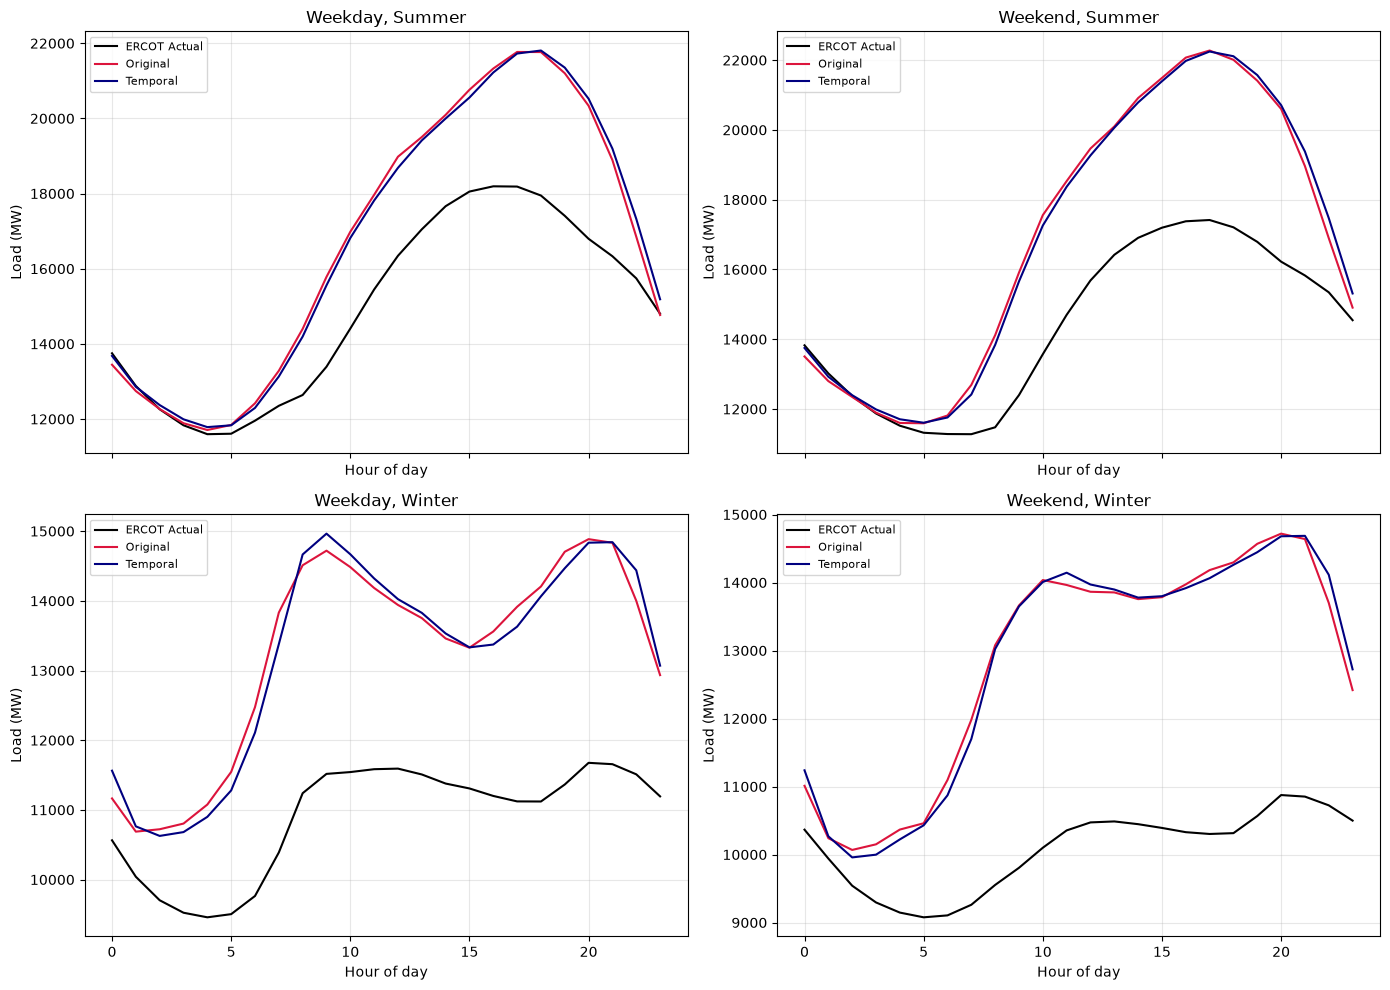

Correlation of average diurnal SHAPE (not level) vs ERCOT, per condition:
  Weekday, Summer      Original r=0.9757   Temporal r=0.9808
  Weekend, Summer      Original r=0.9483   Temporal r=0.9610
  Weekday, Winter      Original r=0.8739   Temporal r=0.9192
  Weekend, Winter      Original r=0.7668   Temporal r=0.8047


In [5]:
def diurnal_profile(series, weekday, summer):
    idx = series.index
    is_weekday = idx.dayofweek < 5
    is_summer = idx.month.isin([6, 7, 8])
    is_winter = idx.month.isin([12, 1, 2])
    season_mask = is_summer if summer else is_winter
    day_mask = is_weekday if weekday else ~is_weekday
    sub = series[season_mask & day_mask]
    return sub.groupby(sub.index.hour).mean()


fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharex=True)
configs = [(True, True, "Weekday, Summer"), (False, True, "Weekend, Summer"),
           (True, False, "Weekday, Winter"), (False, False, "Weekend, Winter")]

for ax, (weekday, summer, title) in zip(axes.flat, configs):
    for series, label, color in [(y_actual, "ERCOT Actual", "black"),
                                  (y_orig, "Original", "crimson"),
                                  (y_temp, "Temporal", "navy")]:
        prof = diurnal_profile(series, weekday, summer)
        ax.plot(prof.index, prof.values, label=label, color=color, linewidth=1.5)
    ax.set_title(title)
    ax.set_xlabel("Hour of day")
    ax.set_ylabel("Load (MW)")
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

print("Correlation of average diurnal SHAPE (not level) vs ERCOT, per condition:")
for weekday, summer, title in configs:
    actual_prof = diurnal_profile(y_actual, weekday, summer)
    orig_prof = diurnal_profile(y_orig, weekday, summer)
    temp_prof = diurnal_profile(y_temp, weekday, summer)
    print(f"  {title:20s} Original r={actual_prof.corr(orig_prof):.4f}   Temporal r={actual_prof.corr(temp_prof):.4f}")


#### Seasonal behavior — monthly average load

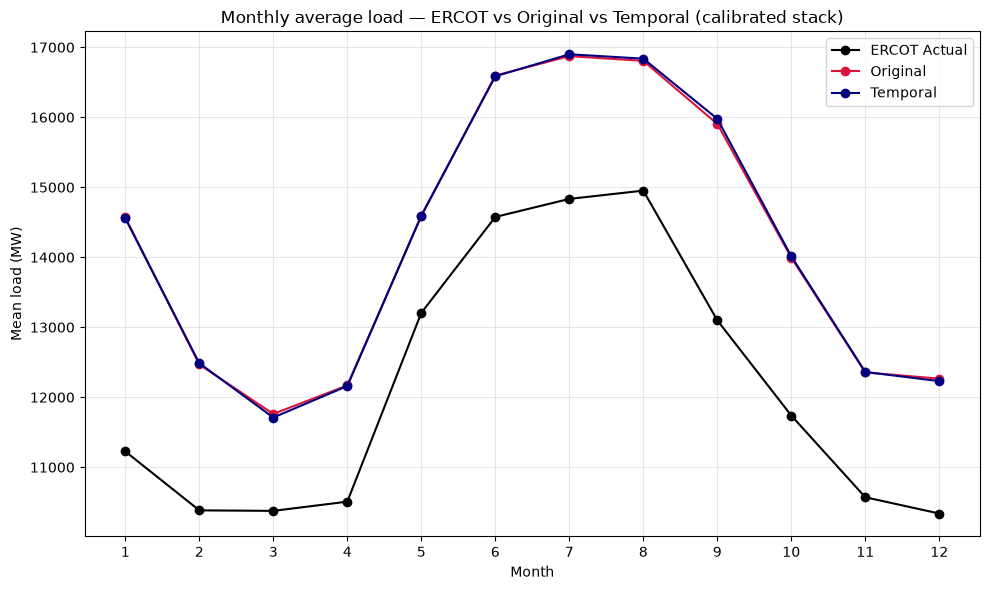

,ERCOT_Actual,Original,Temporal,Original_Bias_%,Temporal_Bias_%
date_time,,,,,
1,11225.74,14568.42,14555.90,29.78,29.67
2,10383.64,12467.72,12485.21,20.07,20.24
3,10376.50,11761.36,11710.22,13.35,12.85
4,10507.86,12169.15,12159.90,15.81,15.72
5,13205.84,14591.55,14594.33,10.49,10.51
6,14575.76,16595.82,16585.73,13.86,13.79
7,14833.67,16873.47,16899.89,13.75,13.93
8,14952.01,16805.75,16837.53,12.40,12.61
9,13098.90,15904.31,15978.11,21.42,21.98


In [6]:
monthly_actual = y_actual.groupby(y_actual.index.month).mean()
monthly_orig = y_orig.groupby(y_orig.index.month).mean()
monthly_temp = y_temp.groupby(y_temp.index.month).mean()

fig, ax = plt.subplots(figsize=(10, 6))
months = monthly_actual.index
ax.plot(months, monthly_actual.values, marker="o", label="ERCOT Actual", color="black")
ax.plot(months, monthly_orig.values, marker="o", label="Original", color="crimson")
ax.plot(months, monthly_temp.values, marker="o", label="Temporal", color="navy")
ax.set_xticks(range(1, 13))
ax.set_xlabel("Month")
ax.set_ylabel("Mean load (MW)")
ax.set_title("Monthly average load — ERCOT vs Original vs Temporal (calibrated stack)")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

monthly_compare = pd.DataFrame({
    "ERCOT_Actual": monthly_actual, "Original": monthly_orig, "Temporal": monthly_temp,
})
monthly_compare["Original_Bias_%"] = (monthly_compare["Original"] / monthly_compare["ERCOT_Actual"] - 1) * 100
monthly_compare["Temporal_Bias_%"] = (monthly_compare["Temporal"] / monthly_compare["ERCOT_Actual"] - 1) * 100
monthly_compare.round(2)


#### Spatial consistency (documented proxy, not a true spatial validation)

There is **no per-bus ground truth** to validate against — ERCOT only publishes the Coast-zone aggregate, not bus-level actuals. A genuine spatial correlation validation (e.g. against feeder-level or substation-level metered data) is not possible with the data currently on hand.

As a partial, weaker sanity check, this computes the correlation between each bus's total annual estimated energy and the number of buildings / sqft assigned to that bus. A high correlation is expected by construction (the model output is buildings-per-bus x a per-building profile, so this mostly confirms the multiplication step didn't introduce artifacts) — it is **not** independent evidence that the spatial *allocation* itself is correct. Framed honestly in case this shows up in the paper.

In [7]:
final_bus_counts = pd.read_csv(exports / "final_bus_building_counts.csv")
final_bus_counts["Bus_Number"] = final_bus_counts["Bus_Number"].astype(str)
final_bus_counts["total_res_buildings"] = final_bus_counts[
    ["single-family_detached", "single-family_attached",
     "multi-family_with_2_-_4_units", "multi-family_with_5plus_units", "mobile_home"]
].sum(axis=1)

bus_sqft = pd.read_csv(exports / "bus_commercial_sqft.csv", index_col=0)
bus_sqft.index = bus_sqft.index.astype(str)
bus_sqft["total_sqft"] = bus_sqft.sum(axis=1)

res_annual_energy = res_temp.sum(axis=0)  # kWh/year per bus, temporal (honest) model
res_annual_energy.index = res_annual_energy.index.astype(str)
com_annual_energy = com_temp.sum(axis=0)
com_annual_energy.index = com_annual_energy.index.astype(str)

res_check = final_bus_counts.set_index("Bus_Number")["total_res_buildings"].to_frame()
res_check["annual_energy_kwh"] = res_annual_energy
res_corr = res_check["total_res_buildings"].corr(res_check["annual_energy_kwh"])

com_check = bus_sqft[["total_sqft"]].copy()
com_check["annual_energy_kwh"] = com_annual_energy
com_corr = com_check["total_sqft"].corr(com_check["annual_energy_kwh"])

print(f"Residential: corr(building count per bus, annual energy per bus) = {res_corr:.4f}")
print(f"Commercial:  corr(sqft per bus, annual energy per bus)           = {com_corr:.4f}")
print("\n(Expected to be high by construction — see caveat above. Reported for completeness, "
      "not as proof of spatial validity.)")


Residential: corr(building count per bus, annual energy per bus) = 0.9479
Commercial:  corr(sqft per bus, annual energy per bus)           = 0.8918

(Expected to be high by construction — see caveat above. Reported for completeness, not as proof of spatial validity.)


#### Out of scope: comparison against "Hanyue's proportional load allocation method" (PI review point 9)

The PI's review asked for a quantitative comparison against a prior synthetic-grid load allocation method (proportional allocation, referenced as "Hanyue's" paper). Implementing that baseline requires the actual method description (which quantity is allocated proportionally to what, at what granularity) that isn't available in this repo or notebook history. Flagging this explicitly rather than guessing at an implementation — need the paper reference or method summary before this can be built.

#### Summary

- **Coincidence/diversity factor**: quantifies how much the per-bus peaks are smoothed out by diversity when aggregated — a genuinely new angle versus the single system-level correlation, and unaffected by the RES_SCALE/COM_SCALE calibration debate (PI point 4).
- **Load duration curve**: shows whether the estimated stack matches ERCOT's load factor (baseload vs peaking behavior), not just its hour-by-hour correlation.
- **Diurnal shape**: separately validates the daily cycle across 4 weekday/weekend x summer/winter conditions, showing whether the model captures behavioral (weekday/weekend) and thermal (summer/winter) modulation independently.
- **Seasonal monthly bias**: shows which months are over/under-estimated, more actionable than a single annual correlation number for deciding where the industrial-baseline assumption (PI point 4) is most wrong.
- **Spatial consistency**: honestly scoped as a weak sanity check, not a true spatial validation, given no per-bus ground truth exists.
- **Hanyue's method comparison**: needs the PI or Seri to share the reference method before it can be implemented.